# Resilience Rewired: discovery

What the Tangerine bank data says about financial resilience, and what the engine should do about it. Every account figure uses the README's judging definitions unless it says otherwise.

## Biggest finding

**The runway formula assumes spending stays flat after a shock, and real customers almost never do that.**

We found 735 real income collapses across 480 accounts, where money in stayed below 55% of normal for at least 3 months. Spending stayed within 10% of usual in only 5% of them. After three months, the flat-spending formula put 493 of these accounts below zero, but only 31 actually were. The median account lost about 40% of what the formula predicted.

The response depends on the starting buffer, measured in months of usual spending:

| Starting buffer | Events | Spending vs usual |
| :-- | --: | --: |
| Under 2 months | 410 | 37% |
| 2 to 6 months | 219 | 71% |
| 6+ months | 106 | 247% |

These are falls in deposits, not confirmed job losses, and nearly all are on cash-only accounts. Section 5 sets out the limits.

## Other findings

| # | Finding | Evidence | Section |
| --: | :-- | :-- | --: |
| 1 | A job loss is the shock that matters | 35% of accounts last under 6 months on EI, and few are that short with no shock | 2 |
| 2 | There are three kinds of customer | 2,894 cash-only, 866 transfer and 740 pension accounts. A layoff doesn't fit pensioners | 3 |
| 3 | Higher earners look more fragile | Top income band: 70% under 6 months with a 2.6x larger buffer than the lowest band, where 4% are | 4 |
| 4 | Runway barely reflects savings | Rank correlation with buffer is -0.04, against -0.68 with income | 4 |
| 5 | Lifetime medians miss recent loans | Fixed costs show $0 loan payment on 197 of 448 running loans, a median $2,545 a month | 6 |
| 6 | The lowest balance predicts default | AUC 0.85, against 0.72 for average balance and 0.67 for payment-to-income | 7 |
| 7 | One simple warning line works | A lowest balance under 1 payment flags 173 loans, 34% of which default, against 3.3% for the rest | 7 |
| 8 | Timing changes the cost of a shock | The next 3 months cost 1.34x typical from November and 0.90x from February | 8 |
| 9 | District data doesn't help | Salary, unemployment, urban ratio and crime all correlate at about 0 with runway | 9 |

Section 10 lists accounts likely to break a live demo, and section 11 turns all this into engine requirements.

## Run it

```
uv venv .venv && uv pip install --python .venv/bin/python -r requirements.txt
.venv/bin/jupyter lab discovery.ipynb
```

Run all cells from the `Tangerine` folder; it takes under a minute. The final cell fails if a number above stops matching the analysis.

## 1. Setup and data checks

Loads the CSVs and stops if the facts this analysis relies on no longer hold. Column definitions are in [`docs/data_model.md`](docs/data_model.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import rankdata, spearmanr

pd.set_option("display.max_columns", 40, "display.width", 160)
pd.options.display.float_format = "{:,.2f}".format

DATA = "data/"
ms = pd.read_csv(DATA + "monthly_summary.csv").sort_values(["account_id", "month"], ignore_index=True)
loans = pd.read_csv(DATA + "loans.csv")
accounts = pd.read_csv(DATA + "accounts.csv")
clients = pd.read_csv(DATA + "clients.csv", parse_dates=["birth_date"])
dispositions = pd.read_csv(DATA + "dispositions.csv")
districts = pd.read_csv(DATA + "districts.csv")
tx = pd.read_csv(DATA + "transactions.csv", usecols=["account_id", "operation", "purpose", "amount"])

# Some rows write this as 4.0, so cast it (see docs/data_model.md).
ms["days_below_zero"] = ms["days_below_zero"].astype(int)
ms["fixed"] = ms.household_bills + ms.insurance + ms.loan_payments

IN_PARTS = ["cash_deposits", "transfers_in", "pension_in", "interest_in"]
OUT_PARTS = ["household_bills", "insurance", "loan_payments", "bank_fees",
             "cash_withdrawals_genuine", "card_withdrawals", "transfers_out_other"]

assert len(ms) == 185_326 and len(accounts) == 4_500 and len(loans) == 682 and len(tx) == 1_056_320
assert not ms.duplicated(["account_id", "month"]).any()
assert loans.account_id.is_unique
assert (ms[IN_PARTS].sum(axis=1) - ms.money_in).abs().max() < 0.02
assert (ms[OUT_PARTS].sum(axis=1) - ms.money_out).abs().max() < 0.02
print(f"{ms.account_id.nunique():,} accounts, {len(ms):,} account-months, {ms.month.min()} to {ms.month.max()}. Checks passed.")

4,500 accounts, 185,326 account-months, 2020-01 to 2025-12. Checks passed.


In [2]:
# Chart style. Colours passed scripts/validate_palette.js from the dataviz method.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
BANDS = ["#104281", "#1c5cab", "#2a78d6", "#5598e7", "#86b6ef"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 130, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK2, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.7,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 2,
})

## 2. Baseline: the judges' numbers for every account

These use the README definitions exactly, so anything later that differs is a deliberate choice.

In [3]:
def runway(buffer, gap):
    """README runway: buffer left / monthly shortfall, capped at 120 months, 1 decimal."""
    buffer, gap = np.asarray(buffer, float), np.asarray(gap, float)
    safe_gap = np.where(gap > 0, gap, np.nan)
    months = np.where(buffer <= 0, 0.0, np.where(gap <= 0, 120.0, np.minimum(buffer / safe_gap, 120.0)))
    return pd.Series(np.round(months, 1))

by = ms.groupby("account_id")
last6 = ms.groupby("account_id").tail(6).groupby("account_id")

m = pd.DataFrame({
    "I": by.money_in.median(), "S": by.money_out.median(), "F": by.fixed.median(),
    "H": by.household_bills.median(), "LP": by.loan_payments.median(),
    "B": last6.avg_daily_balance.mean(), "months": by.size(), "last_month": by.month.last(),
})
m = m.join(loans.set_index("account_id")[["status", "monthly_payment", "defaulted", "loan_start"]])
m["P"] = np.where(m.status.isin(["C", "D"]), m.monthly_payment, 0.0)  # C and D are the running loans

def scenarios(m):
    return {
        "No shock": runway(m.B, m.S - m.I),
        "Repair: one month of spending": runway(m.B - m.S, m.S - m.I),
        "Job loss: EI at 55%": runway(m.B, m.S - 0.55 * m.I),
        "Job loss + bills up 15%": runway(m.B, m.S + 0.15 * m.H - 0.55 * m.I),
    }
for name, r in scenarios(m).items():
    m[name] = r.values
m["ei"] = m["Job loss: EI at 55%"]

display(m[["I", "S", "F", "H", "P", "B"]].describe(percentiles=[.1, .25, .5, .75, .9]).drop("count").round(0))

edges, labels = [-1, 3, 6, 12, 119.99, 121], ["Under 3 months", "3 to 6", "6 to 12", "12 to 120", "No shortfall or 120+"]
scenario_names = list(scenarios(m))
band_share = pd.DataFrame({s: pd.cut(m[s], edges, labels=labels, right=False).value_counts(normalize=True).reindex(labels) * 100
                           for s in scenario_names}).T
display(band_share.round(1))

,I,S,F,H,P,B
mean,"9,329.00","8,717.00","2,220.00","1,948.00",255.00,"25,083.00"
std,"7,438.00","7,086.00","2,176.00","1,975.00",883.00,"13,260.00"
min,0.00,0.00,0.00,0.00,0.00,"-17,267.00"
10%,"2,068.00","1,482.00",0.00,0.00,0.00,"10,720.00"
25%,"3,380.00","2,495.00",11.00,0.00,0.00,"14,208.00"
50%,"7,568.00","7,389.00","1,774.00","1,537.00",0.00,"22,325.00"
75%,"13,280.00","13,028.00","3,416.00","2,980.00",0.00,"33,815.00"
90%,"20,033.00","18,457.00","5,239.00","4,876.00",0.00,"44,850.00"
max,"43,626.00","40,408.00","13,051.00","9,565.00","6,236.00","73,360.00"


,Under 3 months,3 to 6,6 to 12,12 to 120,No shortfall or 120+
No shock,1.30,1.30,2.70,16.00,78.70
Repair: one month of spending,6.30,2.40,4.10,11.70,75.50
Job loss: EI at 55%,9.70,25.40,25.60,31.60,7.70
Job loss + bills up 15%,11.20,27.50,25.70,30.30,5.40


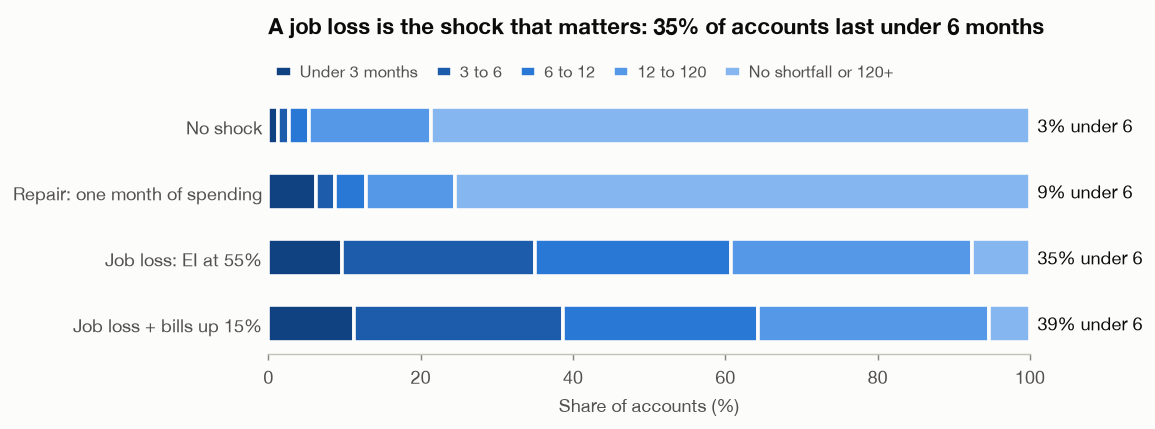

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(band_share))
ypos = np.arange(len(band_share))[::-1]
for label, colour in zip(labels, BANDS):
    vals = band_share[label].values
    ax.barh(ypos, vals, left=left, color=colour, edgecolor=SURFACE, linewidth=2, height=0.56, label=label)
    left += vals
under6 = band_share[labels[:2]].sum(axis=1).values
for y, v in zip(ypos, under6):
    ax.text(101, y, f"{v:.0f}% under 6", va="center", color=INK)
ax.set_yticks(ypos, band_share.index)
ax.set_xlim(0, 100); ax.set_xlabel("Share of accounts (%)")
ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
ax.set_title("A job loss is the shock that matters: 35% of accounts last under 6 months", pad=34)
ax.legend(ncols=5, loc="lower left", bbox_to_anchor=(-0.01, 1.0), fontsize=9, handlelength=1, columnspacing=1.1, handletextpad=0.5)
plt.tight_layout(); plt.show()

**Reading this:** on their own numbers, most accounts look comfortable until income drops. A one-off repair moves far fewer accounts, because only about 4% of buffers are smaller than a month of spending. The rest of this notebook asks whether those job-loss numbers can be trusted.

## 3. Who the customers are: three kinds of income

`money_in` means different things on different accounts, so each account is classed by its source of income.

In [5]:
parts = by[IN_PARTS + ["money_in", "cash_withdrawals_genuine", "money_out"]].sum()
m["income_type"] = np.select([parts.pension_in > 0, parts.transfers_in > 0], ["Pension", "Transfers"], "Cash only")

owner = dispositions[dispositions.type == "owner"].merge(clients, on="client_id").set_index("account_id")
m["age"] = (pd.Timestamp("2025-12-31") - owner.birth_date).dt.days / 365.25
m["home_salary"] = owner.district_id.map(districts.set_index("district_id").average_salary)
m["has_loan"] = m.status.notna()

share = parts.assign(income_type=m.income_type)
source_share = pd.Series({
    "Cash only": (parts.cash_deposits / parts.money_in)[m.income_type == "Cash only"].median(),
    "Transfers": (parts.transfers_in / parts.money_in)[m.income_type == "Transfers"].median(),
    "Pension": (parts.pension_in / parts.money_in)[m.income_type == "Pension"].median(),
}, name="main_source_share_%") * 100

types = m.groupby("income_type").agg(
    accounts=("I", "size"), median_age=("age", "median"), I=("I", "median"), S=("S", "median"), B=("B", "median"),
    ei_runway=("ei", "median"), under_6m_pct=("ei", lambda x: (x < 6).mean() * 100),
    loans=("has_loan", "sum"), default_rate_pct=("defaulted", lambda x: x.mean() * 100),
).join(source_share)
display(types.round(1))

age_65 = m[m.age >= 65]
print(f"Everyone aged 65+ has a pension: {age_65.income_type.eq('Pension').sum()} of {len(age_65)}.")
print(f"Accounts with a pension and a loan: {(m.income_type.eq('Pension') & m.has_loan).sum()}.")

totals = tx.groupby("operation").amount.sum()
bills = tx[tx.purpose.isin(["household bills", "insurance"])]
print(f"Cash is {ms.cash_deposits.sum() / ms.money_in.sum():.0%} of all money in and {ms.cash_withdrawals_genuine.sum() / ms.money_out.sum():.0%} of all money out.")
print(f"Only {bills.operation.eq('bill payment').mean():.1%} of bill and insurance payments use the 'bill payment' operation; the rest are transfers out. Filter on purpose.")

,accounts,median_age,I,S,B,ei_runway,under_6m_pct,loans,default_rate_pct,main_source_share_%
income_type,,,,,,,,,,
Cash only,2894,39.30,"9,751.20","9,662.40","26,696.60",6.80,42.60,472,13.30,99.10
Pension,740,71.60,"3,529.80","2,380.90","14,335.00",35.40,1.20,0,NaN,98.10
Transfers,866,39.30,"3,008.10","2,721.00","18,295.40",10.40,38.90,210,6.20,97.30


Everyone aged 65+ has a pension: 638 of 638.
Accounts with a pension and a loan: 0.
Cash is 75% of all money in and 76% of all money out.
Only 2.1% of bill and insurance payments use the 'bill payment' operation; the rest are transfers out. Filter on purpose.


**Why this matters:**

- **A job-loss twist doesn't fit pensioners.** Their income is a pension and doesn't stop with a layoff, so the engine should say so, not just apply 55%.
- **Almost two-thirds of accounts have income that can't be checked.** On cash-only accounts, nothing shows whether a deposit is pay, business takings or the customer's own money moved around.

## 4. The income paradox: higher earners look more fragile

If runway measured financial health, people with more money should last longer. The formula says the opposite.

,I,S,B,ei_runway,under_6m_pct,cash_only_pct,buffer_in_months_of_spending
income_band,,,,,,,
Lowest,"2,067.70","1,536.40","13,599.10",42.20,4.40,36.00,8.50
Low,"3,817.60","2,858.10","15,496.40",23.10,8.10,33.20,5.80
Middle,"7,568.30","7,276.60","22,772.70",7.00,41.70,94.20,3.00
High,"12,257.50","11,860.90","29,293.90",5.90,50.70,89.40,2.50
Highest,"20,045.60","18,395.50","35,417.10",4.50,70.40,68.70,1.80


Rank correlation with job-loss runway: income -0.68, spending -0.79, buffer -0.04


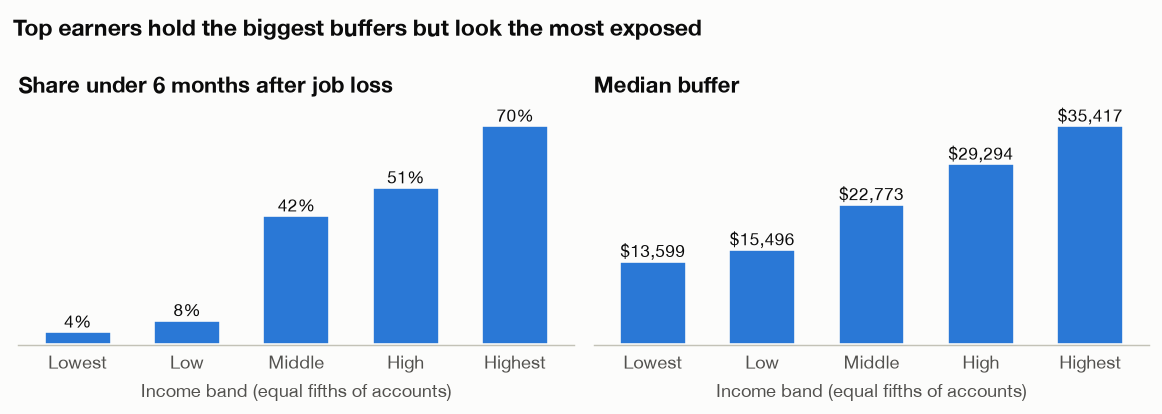

In [6]:
m["income_band"] = pd.qcut(m.I, 5, labels=["Lowest", "Low", "Middle", "High", "Highest"])
paradox = m.groupby("income_band", observed=True).agg(
    I=("I", "median"), S=("S", "median"), B=("B", "median"), ei_runway=("ei", "median"),
    under_6m_pct=("ei", lambda x: (x < 6).mean() * 100), cash_only_pct=("income_type", lambda x: x.eq("Cash only").mean() * 100))
paradox["buffer_in_months_of_spending"] = m.assign(x=m.B / m.S.where(m.S > 0)).groupby("income_band", observed=True).x.median()
display(paradox.round(1))

rho = lambda a, b: spearmanr(a, b).statistic
print(f"Rank correlation with job-loss runway: income {rho(m.I, m.ei):+.2f}, spending {rho(m.S, m.ei):+.2f}, buffer {rho(m.B, m.ei):+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, col, title, fmt in [(axes[0], "under_6m_pct", "Share under 6 months after job loss", "{:.0f}%"),
                            (axes[1], "B", "Median buffer", "${:,.0f}")]:
    v = paradox[col].values
    ax.bar(range(5), v, color=BLUE, width=0.62, edgecolor=SURFACE, linewidth=2)
    ax.set_xticks(range(5), paradox.index); ax.set_title(title)
    ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.tick_params(axis="x", length=0)
    ax.set_xlabel("Income band (equal fifths of accounts)")
    for i in range(5):
        ax.text(i, v[i], fmt.format(v[i]), ha="center", va="bottom", color=INK, fontsize=9.5)
plt.suptitle("Top earners hold the biggest buffers but look the most exposed", x=0.012, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout(); plt.show()

In [7]:
# Is the money coming in plausibly pay? Compare it with average salary in the owner's home district.
ratio = m.I / m.home_salary
income_check = pd.DataFrame({
    "median_I_vs_district_salary": ratio.groupby(m.income_type).median(),
    "I_above_district_salary_pct": (ratio > 1).groupby(m.income_type).mean() * 100,
    "I_above_2x_district_salary_pct": (ratio > 2).groupby(m.income_type).mean() * 100,
})
display(income_check.round(2))
print(f"Highest district average salary: ${districts.average_salary.max():,.0f}. Top income band median: ${paradox.loc['Highest', 'I']:,.0f}.")

# Sensitivity: the same paradox on accounts whose income is identifiable.
for t in ["Cash only", "Transfers", "Pension"]:
    x = m[m.income_type == t]
    print(f"{t:10} income vs runway rank correlation {rho(x.I, x.ei):+.2f}")

,median_I_vs_district_salary,I_above_district_salary_pct,I_above_2x_district_salary_pct
income_type,,,
Cash only,1.64,72.05,36.83
Pension,0.59,0.00,0.00
Transfers,0.53,49.31,38.80


Highest district average salary: $7,892. Top income band median: $20,046.
Cash only  income vs runway rank correlation -0.45
Transfers  income vs runway rank correlation -0.78
Pension    income vs runway rank correlation -0.26


**Reading this:** the 45% income cut scales with how much money flows through the account, and flow varies far more than buffers do. So runway mostly ranks accounts by flow. It's not really a measure of savings.

Many "incomes" also sit far above any district's average salary, on both cash-only and transfer accounts, which suggests a lot of that flow isn't pay. Some could be two earners sharing an account, so this is suggestive and doesn't prove it. The README also says EI has a weekly maximum, and the 55% rule ignores it, so real high earners would lose even more income than this shows.

## 5. Biggest finding: when income really collapses, spending doesn't stay flat

The formula assumes spending stays at its usual level after a shock. The data lets us test that, because some accounts really did lose their income.

**Test:** find every period where `money_in` stayed below 55% of the account's trailing 12-month median for at least 3 months in a row, the same threshold as the EI twist. Accounts with no usual spending are left out, because there is nothing to compare with. Then compare what the flat-spending formula predicted with what actually happened to the balance.

In [8]:
def find_events(ms, threshold=0.55, min_months=3):
    """Runs of at least min_months with income below threshold x trailing 12-month median."""
    rows = []
    for account, x in ms.groupby("account_id", sort=False):
        money_in, money_out = x.money_in.to_numpy(), x.money_out.to_numpy()
        base_in = x.money_in.shift(1).rolling(12, min_periods=12).median().to_numpy()
        base_out = x.money_out.shift(1).rolling(12, min_periods=12).median().to_numpy()
        low = (money_in < threshold * base_in) & (base_in > 0)
        ends, mins, months = x.month_end_balance.to_numpy(), x.min_balance.to_numpy(), x.month.to_numpy()
        i, n = 0, len(x)
        while i <= n - min_months:
            if low[i:i + min_months].all():
                j = i + min_months
                while j < n and low[j]:
                    j += 1
                k = i + min_months
                rows.append(dict(account_id=account, start=months[i], start_pos=i, length=j - i, ran_to_end=j == n,
                                 base_in=base_in[i], base_out=base_out[i], start_balance=ends[i - 1],
                                 in_mean=money_in[i:k].mean(), out_mean=money_out[i:k].mean(),
                                 end_balance=ends[k - 1], lowest=mins[i:k].min()))
                i = j
            else:
                i += 1
    e = pd.DataFrame(rows)
    e = e[e.base_out > 0].copy()
    e["income_kept"] = e.in_mean / e.base_in
    e["spending_kept"] = e.out_mean / e.base_out
    e["predicted_loss"] = min_months * (e.base_out - e.in_mean)   # spending stays flat
    e["actual_loss"] = e.start_balance - e.end_balance
    e["predicted_end"] = e.start_balance - e.predicted_loss
    e["pass_through"] = (e.base_out - e.out_mean) / (e.base_in - e.in_mean)
    e["income_type"] = e.account_id.map(m.income_type)
    return e

events = find_events(ms)
def summarise(e):
    return pd.Series({
        "events": len(e), "accounts": e.account_id.nunique(),
        "income_kept_%": e.income_kept.median() * 100, "spending_kept_%": e.spending_kept.median() * 100,
        "predicted_loss": e.predicted_loss.median(), "actual_loss": e.actual_loss.median(),
        "actual_vs_predicted_%": (e.actual_loss / e.predicted_loss)[e.predicted_loss > 0].median() * 100,
        "formula_says_below_0": (e.predicted_end < 0).sum(), "actually_ended_below_0": (e.end_balance < 0).sum(),
        "actually_dipped_below_0": (e.lowest < 0).sum(),
    })
display(summarise(events).to_frame("All events").T.round(1))
print(events.income_type.value_counts().to_string())
print(f"Spending cut by at least 25% in {(events.spending_kept <= .75).mean():.0%} of events; within 10% of usual in {events.spending_kept.between(.9, 1.1).mean():.0%}.")
print(f"Median length {events.length.median():.0f} months. {events.ran_to_end.mean():.0%} were still going at the end of the account's data.")

,events,accounts,income_kept_%,spending_kept_%,predicted_loss,actual_loss,actual_vs_predicted_%,formula_says_below_0,actually_ended_below_0,actually_dipped_below_0
All events,735.00,480.00,13.30,50.10,"48,348.50","18,205.70",40.20,493.00,31.00,43.00


income_type
Cash only    734
Transfers      1
Spending cut by at least 25% in 73% of events; within 10% of usual in 5%.
Median length 3 months. 5% were still going at the end of the account's data.


t,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8,9
Money in,101.00,99.00,96.00,90.00,87.00,129.00,2.00,10.00,11.00,35.00,39.00,37.00,38.00,42.00,40.00,44.00
Money out,100.00,103.00,101.00,99.00,88.00,104.00,79.00,36.00,24.00,31.00,39.00,45.00,46.00,54.00,55.00,54.00


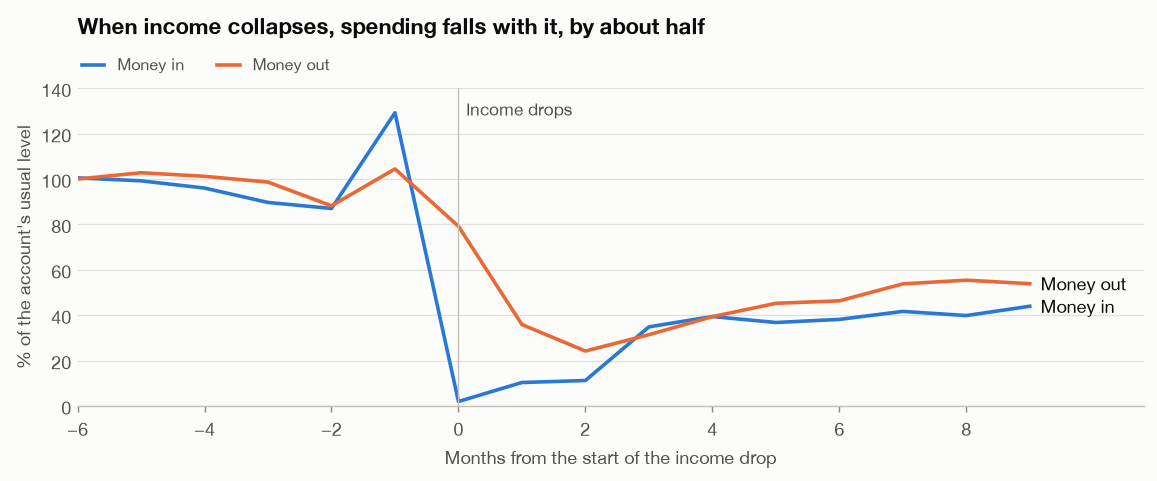

In [9]:
# Event study: line up every event at month 0 and index to the account's pre-drop level.
lines = []
frames = {a: x.reset_index(drop=True) for a, x in ms[["account_id", "money_in", "money_out"]].groupby("account_id")}
for e in events.itertuples():
    x = frames[e.account_id]
    for t in range(-6, 10):
        pos = e.start_pos + t
        if 0 <= pos < len(x):
            lines.append((t, x.money_in[pos] / e.base_in * 100, x.money_out[pos] / e.base_out * 100))
study = pd.DataFrame(lines, columns=["t", "Money in", "Money out"]).groupby("t").median()
display(study.T.round(0))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.grid(axis="y"); ax.set_axisbelow(True)
ax.plot(study.index, study["Money in"], color=BLUE, label="Money in")
ax.plot(study.index, study["Money out"], color=ORANGE, label="Money out")
ax.axvline(0, color=AXIS, linewidth=0.8)
ax.text(0.12, 128, "Income drops", color=INK2, fontsize=9.5)
ax.annotate("Money out", (study.index[-1], study["Money out"].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK)
ax.annotate("Money in", (study.index[-1], study["Money in"].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=INK)
ax.set_xlim(-6, 10.8); ax.set_ylim(0, 140); ax.set_xticks(range(-6, 10, 2))
ax.set_xlabel("Months from the start of the income drop"); ax.set_ylabel("% of the account's usual level")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_title("When income collapses, spending falls with it, by about half", pad=30)
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(-0.01, 1.0), fontsize=9, handlelength=1.4)
plt.tight_layout(); plt.show()

**Reading the chart:** month 0 is low by construction, since that's how events are chosen, so the informative line is money out. Money in also spikes just before the drop, which may be a last large deposit. The data can't say why.

### Does it hold up?

A finding this large should be attacked before it's presented, so each row below changes something that could have produced it by accident.

In [10]:
robust = {
    "Base: below 55% for 3+ months": events,
    "Stricter: below 40% for 3+ months": find_events(ms, 0.40, 3),
    "Longer: below 55% for 6+ months": find_events(ms, 0.55, 6),
    "Excludes January starts (spending peak)": events[events.start.str[5:] != "01"],
    "Excludes events at the end of the data": events[~events.ran_to_end],
}
robust_table = pd.DataFrame({k: summarise(v) for k, v in robust.items()}).T
display(robust_table[["events", "income_kept_%", "spending_kept_%", "predicted_loss", "actual_loss", "actual_vs_predicted_%"]].round(0))

low = ms.money_in < 0.55 * by.money_in.transform(lambda x: x.shift(1).rolling(12, min_periods=12).median())
normal_ratio = (ms.money_out / by.money_out.transform(lambda x: x.shift(1).rolling(12, min_periods=12).median()).replace(0, np.nan))
print(f"Control: in months without an income drop, spending is {normal_ratio[~low].median():.0%} of its trailing median.")

,events,income_kept_%,spending_kept_%,predicted_loss,actual_loss,actual_vs_predicted_%
Base: below 55% for 3+ months,735.00,13.00,50.00,"48,349.00","18,206.00",40.00
Stricter: below 40% for 3+ months,505.00,7.00,43.00,"53,036.00","19,011.00",37.00
Longer: below 55% for 6+ months,89.00,9.00,29.00,"108,456.00","22,189.00",20.00
Excludes January starts (spending peak),604.00,13.00,51.00,"45,904.00","16,968.00",40.00
Excludes events at the end of the data,700.00,13.00,49.00,"49,543.00","18,263.00",40.00


Control: in months without an income drop, spending is 101% of its trailing median.


The direction above holds on every cut of the events. The next split doesn't behave the same way, and it changes the conclusion: **what people do depends on how much buffer they started with**.

In [11]:
tier_edges, tier_names = [-np.inf, 2, 6, np.inf], ["Thin: under 2 months", "Middle: 2 to 6 months", "Large: 6+ months"]
events["buffer_months"] = events.start_balance / events.base_out
events["tier"] = pd.cut(events.buffer_months, tier_edges, labels=tier_names, right=False)
tiers = events.groupby("tier", observed=True).agg(
    events=("account_id", "size"), usual_money_in=("base_in", "median"), usual_spending=("base_out", "median"),
    start_balance=("start_balance", "median"), end_balance=("end_balance", "median"),
    spending_kept_pct=("spending_kept", lambda x: x.median() * 100),
    pass_through=("pass_through", "median"),
    predicted_loss=("predicted_loss", "median"), actual_loss=("actual_loss", "median"),
    ended_below_0=("end_balance", lambda x: (x < 0).sum()),
)
tiers["balance_left_pct"] = tiers.end_balance / tiers.start_balance * 100
tiers["end_balance_in_months_of_usual_spending"] = events.assign(x=events.end_balance / events.base_out).groupby("tier", observed=True).x.median()
display(tiers.round(2).T)

tier,Thin: under 2 months,Middle: 2 to 6 months,Large: 6+ months
events,410.00,219.00,106.00
usual_money_in,"26,922.16","19,428.32","2,409.11"
usual_spending,"25,485.50","14,883.56","1,581.26"
start_balance,"30,695.00","44,012.34","35,216.34"
end_balance,"12,649.27","14,765.07","20,306.10"
spending_kept_pct,37.43,71.36,246.94
pass_through,0.70,0.27,-1.21
predicted_loss,"63,864.87","38,059.90","2,552.92"
actual_loss,"16,310.24","26,384.10","10,122.66"
ended_below_0,23.00,8.00,0.00


In [12]:
# What this would do to runway. A scenario, not a forecast, applied only to the cash-only accounts the events come from.
# Each account takes the response of its own buffer tier. Tiers that spent more are left unadjusted, so nothing gets longer because of them.
pt = tiers.pass_through.clip(lower=0, upper=1)
print("Spending cut per $1 of lost income, by buffer tier:", pt.round(2).to_dict())

cash = m.income_type == "Cash only"
account_tier = pd.cut(m.B / m.S.where(m.S > 0), tier_edges, labels=tier_names, right=False)
account_pt = account_tier.map(pt).astype(float).fillna(0)
adjusted_S = np.where(cash, (m.S - account_pt * 0.45 * m.I).clip(lower=0), m.S)
m["ei_adjusted"] = runway(m.B, adjusted_S - 0.55 * m.I).values
compare = pd.DataFrame({
    "Formula: spending stays flat": [m.ei[cash].median(), (m.ei[cash] < 6).mean() * 100, (m.ei < 6).mean() * 100],
    "If spending adjusts as observed": [m.ei_adjusted[cash].median(), (m.ei_adjusted[cash] < 6).mean() * 100, (m.ei_adjusted < 6).mean() * 100],
}, index=["Median runway, cash-only accounts (months)", "Under 6 months, cash-only accounts (%)", "Under 6 months, all accounts (%)"])
display(compare.round(1))

Spending cut per $1 of lost income, by buffer tier: {'Thin: under 2 months': 0.7, 'Middle: 2 to 6 months': 0.27, 'Large: 6+ months': 0.0}


,Formula: spending stays flat,If spending adjusts as observed
"Median runway, cash-only accounts (months)",6.80,12.30
"Under 6 months, cash-only accounts (%)",42.60,9.60
"Under 6 months, all accounts (%)",35.10,13.90


**Conclusion:** flat spending almost never happened, but the change runs in both directions.

- **Thin and middle buffers:** spending falls hard, and the median account still holds a balance after three months. Thin-buffer accounts couldn't have kept spending at their usual rate anyway, so part of that cut may be forced. For both groups the formula overstates the loss.
- **Large buffers:** usual spending is small compared with savings, and spending rises, so these accounts lose more than predicted. For them the formula is too optimistic, though their buffers are large enough to absorb it.

So the flat-spending formula is a useful reference point but a poor forecast. The engine should show it alongside a second number, and the adjusted runway above is an illustration of that second number, not a measured result.

Median income is also still far below usual nine months after the drop, so these look like lasting changes, not one bad quarter.

**What this doesn't prove:**

- **These aren't confirmed job losses.** The data only shows deposits falling. The events are nearly all on cash-only accounts, so they may be businesses slowing or money moving elsewhere.
- **The two explanations can't be separated.** If deposits and withdrawals are partly the same cash going round, they would fall together with no real belt-tightening. Either way, spending doesn't stay flat, but "people cut back" is only one reading.
- **Part of the change may be other money.** Customers may be living on income or savings held elsewhere.
- **It may not transfer to other accounts.** Pension and transfer accounts have almost no events, and these events come mostly from high-flow accounts. An income collapse is also deeper than a 45% EI cut, so the adjusted runway is a rough illustration.

## 6. The loan blind spot in lifetime medians

Medians over an account's whole history can miss recent changes. Loans are where that's easiest to measure.

In [13]:
running = m[m.P > 0]
missed = running[running.LP == 0]
finished_counted = m[(m.has_loan) & (m.P == 0) & (m.LP > 0)]
recent6 = ms.groupby("account_id").tail(6).groupby("account_id").money_out.median()

blind = pd.Series({
    "Running loans": len(running),
    "Running loans where typical fixed costs show $0 of loan payment": len(missed),
    "Median payment missing from F on those accounts ($)": missed.P.median(),
    "Loans started in 2024 or 2025, among those": missed.loan_start.str[:4].isin(["2024", "2025"]).sum(),
    "Finished loans still counted in F": len(finished_counted),
    "Median payment no longer owed but still counted ($)": finished_counted.LP.median(),
    "Recent money out vs S on the missed accounts (median ratio)": (recent6.reindex(missed.index) / missed.S).median(),
    "Recent money out minus S on the missed accounts (median $)": (recent6.reindex(missed.index) - missed.S).median(),
})
display(blind.round(2).to_frame("value"))

,value
Running loans,448.00
Running loans where typical fixed costs show $0 of loan payment,197.00
Median payment missing from F on those accounts ($),"2,545.40"
"Loans started in 2024 or 2025, among those",194.00
Finished loans still counted in F,79.00
Median payment no longer owed but still counted ($),"2,598.89"
Recent money out vs S on the missed accounts (median ratio),1.06
Recent money out minus S on the missed accounts (median $),723.66


**Reading this:** typical fixed costs (F) misses the loan payment on 44% of running loans, mostly recent ones, and still counts payments on some finished ones. For the fixed-cost figure in part 1 of the challenge, use `monthly_payment` for running loans in place of the median.

**Don't simply add the payment to spending.** Recent money out on these accounts is only slightly above S, far less than the loan payment, so taking on a loan seems to displace other spending. This is the same pattern as section 5: spending moves with circumstances.

## 7. Early warning: the lowest balance beats the average

Can we spot who will default using only what was known **before** the loan was granted? Everything below uses months before `loan_start`, so the outcome can't leak in.

In [14]:
pre = ms.merge(loans[["account_id", "loan_start", "monthly_payment", "defaulted"]], on="account_id")
pre = pre[pre.month < pre.loan_start.str[:7]]
window = pre.groupby("account_id").tail(6).groupby("account_id")

p = pd.DataFrame({
    "lowest_balance": window.min_balance.min(), "average_balance": window.avg_daily_balance.mean(),
    "median_income": pre.groupby("account_id").money_in.median(),
    "pre_months": pre.groupby("account_id").size(),
    "ever_negative": pre.groupby("account_id").days_below_zero.max() > 0,
}).join(loans.set_index("account_id")[["monthly_payment", "defaulted", "loan_start", "amount"]])
p["lowest_in_payments"] = p.lowest_balance / p.monthly_payment
p["payment_to_income"] = p.monthly_payment / p.median_income.where(p.median_income > 0)

def auc(score, y):
    keep = ~np.isnan(score)
    score, y = score[keep], y[keep]
    r = rankdata(score)
    n1, n0 = y.sum(), len(y) - y.sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

y = p.defaulted.to_numpy()
signals = {
    "Lowest balance, in loan payments": -p.lowest_in_payments,
    "Lowest balance, $": -p.lowest_balance,
    "Average balance, $ (like buffer B)": -p.average_balance,
    "Payment as a share of income": p.payment_to_income,
    "Loan amount": p.amount,
    "Income": -p.median_income,
}
aucs = pd.Series({k: auc(v.to_numpy(dtype=float), y) for k, v in signals.items()}, name="AUC").sort_values(ascending=False)

rng = np.random.default_rng(42)
a, b = (-p.lowest_in_payments).to_numpy(dtype=float), (-p.average_balance).to_numpy(dtype=float)
diffs = []
for _ in range(2000):
    i = rng.integers(0, len(p), len(p))
    if 0 < y[i].sum() < len(p):
        diffs.append(auc(a[i], y[i]) - auc(b[i], y[i]))
ci = np.percentile(diffs, [2.5, 97.5])
display(aucs.round(3).to_frame())
print(f"Lowest balance vs average balance, AUC gain: {auc(a, y) - auc(b, y):+.3f} (95% bootstrap interval {ci[0]:+.3f} to {ci[1]:+.3f}).")
old = p.loan_start.str[:4] != "2025"
print(f"Excluding 2025 loans, which have had little time to go bad: {auc(a[old], y[old]):.3f} vs {auc(b[old], y[old]):.3f}.")
print(f"Loans: {len(p)}, defaults: {y.sum()}, median pre-loan history: {p.pre_months.median():.0f} months, shortest: {p.pre_months.min()}.")

,AUC
"Lowest balance, in loan payments",0.85
"Lowest balance, $",0.83
"Average balance, $ (like buffer B)",0.72
Payment as a share of income,0.67
Loan amount,0.64
Income,0.57


Lowest balance vs average balance, AUC gain: +0.127 (95% bootstrap interval +0.070 to +0.188).
Excluding 2025 loans, which have had little time to go bad: 0.830 vs 0.710.
Loans: 682, defaults: 76, median pre-loan history: 13 months, shortest: 3.


,loans,defaults,default_rate_%
band,,,
Below $0,21,21,100.00
$0 to 1 payment,152,38,25.00
1 to 3 payments,122,8,6.60
3+ payments,387,9,2.30


Lowest balance under 1 payment: 173 loans (25%), 34% default, catches 59 of 76 defaults. Everyone else: 3.3%.
Any negative balance before the loan: 27 loans, 27 defaulted.


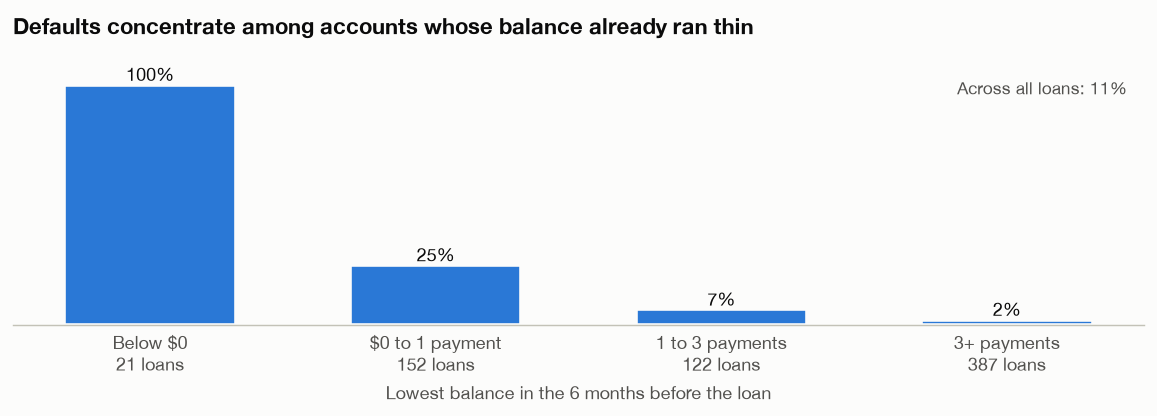

In [15]:
band_edges = [-np.inf, 0, 1, 3, np.inf]
band_names = ["Below $0", "$0 to 1 payment", "1 to 3 payments", "3+ payments"]
p["band"] = pd.cut(p.lowest_in_payments, band_edges, labels=band_names, right=False)
warn = p.groupby("band", observed=True).defaulted.agg(loans="size", defaults="sum")
warn["default_rate_%"] = warn.defaults / warn.loans * 100
display(warn.round(1))

flag = p.lowest_in_payments < 1
print(f"Lowest balance under 1 payment: {flag.sum()} loans ({flag.mean():.0%}), {p.defaulted[flag].mean():.0%} default, catches {p.defaulted[flag].sum()} of {y.sum()} defaults. Everyone else: {p.defaulted[~flag].mean():.1%}.")
print(f"Any negative balance before the loan: {p.ever_negative.sum()} loans, {p.defaulted[p.ever_negative].sum()} defaulted.")

fig, ax = plt.subplots(figsize=(9, 3.3))
v = warn["default_rate_%"].values
ax.bar(range(len(v)), v, color=BLUE, width=0.6, edgecolor=SURFACE, linewidth=2)
for i in range(len(v)):
    ax.text(i, v[i], f"{v[i]:.0f}%", ha="center", va="bottom", color=INK)
ax.set_xticks(range(len(v)), [f"{n}\n{c} loans" for n, c in zip(warn.index, warn.loans)])
rate = y.mean() * 100
ax.text(3.42, 96, f"Across all loans: {rate:.0f}%", ha="right", color=INK2, fontsize=9.5)
ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.tick_params(axis="x", length=0); ax.set_ylim(0, 112)
ax.set_xlabel("Lowest balance in the 6 months before the loan")
ax.set_title("Defaults concentrate among accounts whose balance already ran thin")
plt.tight_layout(); plt.show()

**Why this matters:** buffer B is an average, which hides the low point. The lowest balance measured against the customer's own payment separates defaults far better than income or payment size. It's a simple rule a customer can understand and act on, which makes it a natural goal for a plan: keep your lowest balance above one payment.

**Limits:**

- The thresholds were chosen on this same data, with no holdout, so they may look better than they would on new loans.
- The "all defaulted" groups are small, so treat them as a strong signal, not a certainty.
- Status is as of the end of 2025, so recent loans have had less time to default. Excluding 2025 loans is shown above.
- This data only covers loans the bank approved.

## 8. Seasonality: when a shock hits changes the damage

A single "typical month" hides a strong calendar pattern.

cal,01,02,03,04,05,06,07,08,09,10,11,12
money_in,"7,488.00","7,432.00","7,294.00","7,091.00","6,939.00","10,013.00","7,366.00","7,118.00","7,031.00","6,990.00","6,911.00","9,724.00"
money_out,"11,518.00","4,392.00","5,682.00","5,899.00","6,223.00","9,856.00","5,661.00","5,934.00","6,015.00","6,302.00","6,184.00","7,363.00"


,01,02,03,04,05,06,07,08,09,10,11,12
spending_vs_typical,1.78,0.79,0.94,0.96,1.00,1.50,0.97,0.99,0.99,1.00,1.00,1.24
next_3_months_vs_typical,1.17,0.90,0.97,1.16,1.16,1.15,0.98,0.99,1.00,1.08,1.34,1.27


Worst 3-month start: 11 (1.34x typical). Best: 02 (0.90x).
Money in by income type, median by calendar month:


cal,01,02,03,04,05,06,07,08,09,10,11,12
type,,,,,,,,,,,,
Cash only,"9,716.00","9,671.00","9,541.00","9,366.00","9,330.00","13,676.00","9,757.00","9,449.00","9,402.00","9,399.00","9,294.00","13,489.00"
Pension,"3,543.00","3,519.00","3,541.00","3,523.00","3,539.00","3,528.00","3,528.00","3,524.00","3,528.00","3,530.00","3,536.00","3,530.00"
Transfers,"5,056.00","5,091.00","4,239.00","4,630.00","4,604.00","5,885.00","5,784.00","6,441.00","5,372.00","4,813.00","4,772.00","4,204.00"


Money out, median by year and calendar month (is the pattern stable?):


cal,01,02,03,04,05,06,07,08,09,10,11,12
year,,,,,,,,,,,,
2022,"11,769.00","4,164.00","5,671.00","5,764.00","6,182.00","9,449.00","5,749.00","5,888.00","6,004.00","6,113.00","6,230.00","8,171.00"
2023,"11,535.00","4,216.00","5,140.00","5,325.00","5,849.00","9,005.00","5,266.00","5,673.00","5,741.00","5,908.00","5,917.00","7,835.00"
2024,"11,416.00","4,522.00","5,980.00","6,080.00","6,546.00","10,273.00","5,849.00","6,073.00","6,420.00","6,544.00","6,499.00","8,653.00"
2025,"12,340.00","4,786.00","6,239.00","6,679.00","6,809.00","11,503.00","6,020.00","6,351.00","6,380.00","6,697.00","6,647.00","6,313.00"


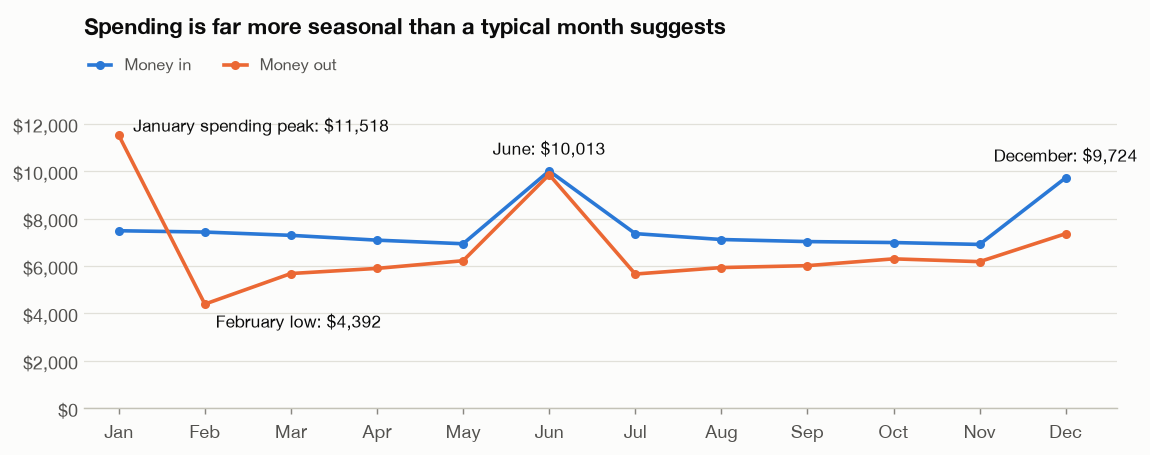

In [16]:
s = ms.assign(cal=ms.month.str[5:], year=ms.month.str[:4], type=ms.account_id.map(m.income_type))
season = s.groupby("cal")[["money_in", "money_out"]].median()
display(season.T.round(0))

ratio = s.assign(r=s.money_out / s.account_id.map(m.S.where(m.S > 0))).groupby("cal").r.median()
three = pd.Series({ratio.index[i]: np.mean([ratio.iloc[(i + k) % 12] for k in range(3)]) for i in range(12)})
start_cost = pd.DataFrame({"spending_vs_typical": ratio, "next_3_months_vs_typical": three})
display(start_cost.T.round(2))
print(f"Worst 3-month start: {three.idxmax()} ({three.max():.2f}x typical). Best: {three.idxmin()} ({three.min():.2f}x).")

print("Money in by income type, median by calendar month:")
display(s.pivot_table(index="type", columns="cal", values="money_in", aggfunc="median").round(0))
print("Money out, median by year and calendar month (is the pattern stable?):")
display(s[s.year >= "2022"].pivot_table(index="year", columns="cal", values="money_out", aggfunc="median").round(0))

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.grid(axis="y"); ax.set_axisbelow(True)
ax.plot(months, season.money_in, color=BLUE, label="Money in", marker="o", markersize=4)
ax.plot(months, season.money_out, color=ORANGE, label="Money out", marker="o", markersize=4)
for label, x, col, off in [("January spending peak", 0, "money_out", (8, 2)), ("June", 5, "money_in", (0, 9)), ("December", 11, "money_in", (0, 9)), ("February low", 1, "money_out", (6, -13))]:
    ax.annotate(f"{label}: ${season[col].iloc[x]:,.0f}", (x, season[col].iloc[x]), xytext=off, textcoords="offset points",
                ha="left" if off[0] > 0 else "center", color=INK, fontsize=9.5)
ax.set_ylim(0, 13500); ax.set_xlim(-0.4, 11.6)
ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_title("Spending is far more seasonal than a typical month suggests", pad=30)
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(-0.01, 1.0), fontsize=9, handlelength=1.4)
plt.tight_layout(); plt.show()

**Why this matters:** money out peaks in January and June in every year shown. Money in jumps in June and December, mostly on cash-only accounts, while pensions stay flat. The formula treats a job loss in November and one in February the same, but the next three months cost about 1.34x and 0.90x a typical month. The buffer's last six rows are also mostly July to December, so they sit on the run-up to the January peak.

**One unexplained item:** December 2025 spending is well below earlier Decembers. It's the last month in the data, so it may be incomplete. Check this before relying on the most recent month.

## 9. What didn't matter

Things that seem like they should matter but barely do, which saves building features around them.

In [17]:
own_d = owner.district_id
d = districts.set_index("district_id")
tests = {
    "District average salary": own_d.map(d.average_salary),
    "District unemployment 2023": own_d.map(d.unemployment_rate_2023),
    "District urban ratio": own_d.map(d.urban_ratio_pct),
    "District crimes per inhabitant": own_d.map(d.crimes_2023 / d.inhabitants),
}
rows = {k: {"vs_job_loss_runway": rho(v.reindex(m.index), m.ei), "vs_buffer": rho(v.reindex(m.index), m.B)} for k, v in tests.items()}
display(pd.DataFrame(rows).T.round(3))
print(f"Income vs job-loss runway for comparison: {rho(m.I, m.ei):+.3f}")

,vs_job_loss_runway,vs_buffer
District average salary,-0.02,0.01
District unemployment 2023,0.01,0.01
District urban ratio,0.00,-0.00
District crimes per inhabitant,-0.01,-0.01


Income vs job-loss runway for comparison: -0.678


**Reading this:** district data has almost no relationship with an account's runway or buffer, so use it for context, not as a driver of the plan. Say that plainly if a judge asks.

## 10. Live-twist traps

A judge can pick any `account_id`, so these are the accounts most likely to break a demo. The engine should handle each one on purpose.

In [18]:
traps = {
    "Typical money in is $0": m.I == 0,
    "Typical spending is $0": m.S == 0,
    "Both money in and spending are $0": (m.I == 0) & (m.S == 0),
    "Buffer is zero or negative": m.B <= 0,
    "Data stops before December 2025": m.last_month != "2025-12",
    "Pension income, so a layoff doesn't fit": m.income_type == "Pension",
    "Household bills are $0, so a bills shock does nothing": m.H == 0,
    "Running loan with $0 in typical fixed costs": (m.P > 0) & (m.LP == 0),
    "Running loan, but no payment in the last month": (m.P > 0) & (by.loan_payments.last() == 0),
}
trap_table = pd.DataFrame([{"Trap": k, "Accounts": int(v.sum()), "Examples": ", ".join(map(str, m.index[v][:3]))} for k, v in traps.items()])
with pd.option_context("display.max_colwidth", None):
    display(trap_table.set_index("Trap"))
print(f"Fixed costs are a median {(m.F / m.S.where(m.S > 0)).median():.0%} of spending, so most spending is not visibly committed.")

,Accounts,Examples
Trap,,
Typical money in is $0,14,"21132, 22682, 26939"
Typical spending is $0,77,"20578, 20866, 20887"
Both money in and spending are $0,10,"21132, 22682, 31500"
Buffer is zero or negative,23,"32078, 36407, 37897"
Data stops before December 2025,76,"20866, 21132, 22682"
"Pension income, so a layoff doesn't fit",740,"20176, 20243, 20253"
"Household bills are $0, so a bills shock does nothing",1225,"20111, 20133, 20189"
Running loan with $0 in typical fixed costs,197,"20208, 20706, 20731"
"Running loan, but no payment in the last month",12,"24640, 40355, 40462"


Fixed costs are a median 31% of spending, so most spending is not visibly committed.


## 11. What this means for the engine

| Finding | What to build |
| :-- | :-- |
| Flat spending almost never happens | Show the judges' flat-spending runway first, then a second "if you adjust" runway, and label it as a scenario |
| Runway ranks flow, not savings | Show buffer in months of spending next to runway, and name the income type |
| Pensions don't stop with a layoff | Flag the mismatch on a job-loss twist, then still give the requested number |
| Lifetime medians go stale | Use `monthly_payment` for running loans in fixed costs, and flag finished ones |
| Lowest balance predicts trouble | Use "keep your lowest balance above one payment" as a plan goal and warning sign |
| Spending is seasonal | Let the shock have a start month, and warn when it runs into January |
| Accounts vary at the edges | Handle every trap in section 10 before the demo |

## 12. Check the headline numbers

In [19]:
# Fails if any number quoted at the top of this notebook stops matching the analysis.
near = lambda a, b, tol=0.5: abs(a - b) <= tol
b_all = summarise(events)
assert b_all.events == 735 and b_all.accounts == 480
assert near(events.spending_kept.between(.9, 1.1).mean() * 100, 5)
assert b_all.formula_says_below_0 == 493 and b_all.actually_ended_below_0 == 31
assert near(b_all["actual_vs_predicted_%"], 40)
assert tiers.events.tolist() == [410, 219, 106]
assert [round(v) for v in tiers.spending_kept_pct] == [37, 71, 247]
assert near(band_share.loc["Job loss: EI at 55%", labels[:2]].sum(), 35)
assert near(band_share.loc["No shock", labels[:2]].sum(), 2.6, 0.1)
assert types.accounts.to_dict() == {"Cash only": 2894, "Pension": 740, "Transfers": 866}
assert round(paradox.loc["Highest", "under_6m_pct"]) == 70 and round(paradox.loc["Lowest", "under_6m_pct"]) == 4
assert near(paradox.loc["Highest", "B"] / paradox.loc["Lowest", "B"], 2.6, 0.05)
assert near(rho(m.B, m.ei), -0.04, 0.005) and near(rho(m.I, m.ei), -0.68, 0.005)
assert len(running) == 448 and len(missed) == 197 and round(missed.P.median()) == 2545
assert round(aucs["Lowest balance, in loan payments"], 2) == 0.85
assert round(aucs["Average balance, $ (like buffer B)"], 2) == 0.72
assert round(aucs["Payment as a share of income"], 2) == 0.67
assert flag.sum() == 173 and round(p.defaulted[flag].mean() * 100) == 34 and round(p.defaulted[~flag].mean() * 100, 1) == 3.3
assert three.idxmax() == "11" and round(three.max(), 2) == 1.34 and three.idxmin() == "02" and round(three.min(), 2) == 0.90
assert max(abs(rows[k]["vs_job_loss_runway"]) for k in rows) < 0.03

print("All headline numbers match the analysis.")

All headline numbers match the analysis.
